<a href="https://colab.research.google.com/github/scudilio/AI---Deep-Learning/blob/main/Aula-01/MBA_DL_Aula_1_02_aplicacao1_cnn_cifar10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 1 | Aplicação 1: Redes Neurais Convolucionais (CNN) com CIFAR-10

## Exercício de fixação: construir, treinar e avaliar uma CNN usando Keras na base de dados CIFAR-10

### MBA FIAP | Deep Learning e Redes Neurais Modernas

### Profa. Juliana Scudilio

**Problema de negócio.** Uma empresa recebe milhares de fotos por dia (produtos, documentos, peças, sinistros) e precisa classificá-las automaticamente. Vamos construir o modelo que faz isso, do dado bruto até a avaliação.

**Base de dados.** CIFAR-10: 60 mil fotos coloridas de 32x32 pixels em 10 categorias (avião, carro, pássaro, gato, cervo, cachorro, sapo, cavalo, navio, caminhão). Para o treino caber em CPU durante a aula, usamos um subconjunto de 10.000 imagens de treino e 2.000 de teste, já incluído no repositório da disciplina. Mais informações em https://www.cs.toronto.edu/~kriz/cifar.html

Cada bloco termina com um ⏱ **Checkpoint**: só seguimos quando todos chegaram.

### Instalando o Keras

O ambiente ML do Databricks já tem o PyTorch. O Keras é a "interface amigável" que vamos usar por cima dele: as mesmas funções `Sequential`, `compile`, `fit` e `evaluate` que aparecem na maioria dos tutoriais. A célula abaixo leva menos de 1 minuto. Rode uma vez.

In [ ]:
%pip install --quiet keras

In [ ]:
# import os

# # Dizemos ao Keras para usar o PyTorch como "motor" por baixo (precisa vir ANTES de importar o keras)
# os.environ["KERAS_BACKEND"] = "torch"

# # No Databricks, reinicia o Python para enxergar a biblioteca recém-instalada
# if "DATABRICKS_RUNTIME_VERSION" in os.environ or os.path.exists("/databricks"):
#     dbutils.library.restartPython()

In [ ]:
import os
os.environ["KERAS_BACKEND"] = "torch"   # repetimos aqui porque o Python foi reiniciado

import numpy as np
import matplotlib.pyplot as plt
import keras

print("Keras", keras.__version__, "| motor:", keras.backend.backend())

Keras 3.13.2 | motor: torch


### Carregando a base CIFAR-10 (imagens rotuladas em 10 categorias)

O arquivo `cifar10_subset.npz` está na pasta `data/` do repositório. Se você importou só o notebook, suba o arquivo para um Volume e informe o caminho em `CAMINHO_MANUAL`.

In [ ]:

import keras
from keras.datasets import cifar10

# carregando o dataset pré-randomizado de treinamento bem como os dados de teste

(x_train, y_train), (x_test, y_test) = cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1670s 10us/step


In [ ]:

import keras
from keras.datasets import cifar10
import numpy as np
from PIL import Image
import zipfile
import io
import csv

# # Carrega a base completa uma única vez
# (x_train, y_train), (x_test, y_test) = cifar10.load_data()

# Quantidades desejadas
qtd_train = 10000
qtd_test = 2000

# Seleciona amostras aleatórias, sem repetição
rng = np.random.default_rng(42)

indices_train = rng.choice(
    len(x_train), size=qtd_train, replace=False
)

indices_test = rng.choice(
    len(x_test), size=qtd_test, replace=False
)

# Nomes das 10 classes do CIFAR-10
classes = [
    "aviao", "carro", "passaro", "gato",
    "cervo", "cachorro", "sapo",
    "cavalo", "navio", "caminhao"
]

# Cria o arquivo ZIP
with zipfile.ZipFile(
    "cifar10_amostra.zip", "w",
    compression=zipfile.ZIP_DEFLATED
) as zipf:

    registros = []

    for conjunto, imagens, rotulos, indices in [
        ("train", x_train, y_train, indices_train),
        ("test", x_test, y_test, indices_test)
    ]:

        for i, indice in enumerate(indices):
            classe = int(rotulos[indice][0])

            # Converte array NumPy em imagem PNG
            imagem = Image.fromarray(imagens[indice])
            buffer = io.BytesIO()
            imagem.save(buffer, format="PNG")

            nome = f"{conjunto}/imagem_{i:03d}.png"

            # Salva dentro do ZIP
            zipf.writestr(nome, buffer.getvalue())

            # Registra o rótulo correspondente
            registros.append([
                nome, classe, classes[classe]
            ])

    # Gera o CSV dentro do ZIP
    texto_csv = io.StringIO()
    writer = csv.writer(texto_csv)
    writer.writerow(["arquivo", "classe", "nome_classe"])
    writer.writerows(registros)

    zipf.writestr(
        "rotulos.csv", texto_csv.getvalue()
    )

print("Arquivo cifar10_amostra.zip criado!")


Arquivo cifar10_amostra.zip criado!


In [ ]:
cifar10_labels = ["avião", "carro", "pássaro", "gato", "cervo", "cachorro", "sapo", "cavalo", "navio", "caminhão"]


In [ ]:
import zipfile
import numpy as np
import pandas as pd
from PIL import Image
import io

with zipfile.ZipFile("cifar10_amostra.zip", "r") as zipf:

    rotulos = pd.read_csv(zipf.open("rotulos.csv"))

    def carregar(conjunto):
        imagens = []
        classes = []

        dados = rotulos[
            rotulos["arquivo"].str.startswith(conjunto + "/")
        ]

        for _, linha in dados.iterrows():
            imagem = Image.open(
                io.BytesIO(zipf.read(linha["arquivo"]))
            ).convert("RGB")

            imagens.append(np.array(imagem))
            classes.append(int(linha["classe"]))

        return np.array(imagens), np.array(classes)

    x_train, y_train = carregar("train")
    x_test, y_test = carregar("test")

print("Treinamento:", x_train.shape)
print("Teste:", x_test.shape)

Treinamento: (10000, 32, 32, 3)
Teste: (2000, 32, 32, 3)


In [ ]:
# CAMINHO_MANUAL = ""   # ex.: "/Volumes/workspace/default/aula1/cifar10_subset.npz"

# # procuramos o arquivo em alguns lugares possíveis
# candidatos = [CAMINHO_MANUAL, "../data/cifar10_subset.npz", "data/cifar10_subset.npz"]
# caminho = next((c for c in candidatos if c and os.path.exists(c)), None)
# assert caminho, "cifar10_subset.npz não encontrado: clone o repositório como Git folder ou informe CAMINHO_MANUAL."

# # carregando o dataset já separado em treinamento e teste
# dados = np.load(caminho)
# x_train, y_train = dados["x_train"], dados["y_train"]
# x_test, y_test = dados["x_test"], dados["y_test"]

# # nomes das 10 classes, em português, na mesma ordem dos rótulos 0 a 9
# cifar10_labels = ["avião", "carro", "pássaro", "gato", "cervo", "cachorro", "sapo", "cavalo", "navio", "caminhão"]

# print("Treino:", x_train.shape, "| Teste:", x_test.shape)
# print("Cada imagem:", x_train.shape[1:], "(altura x largura x canais RGB) | valores de", x_train.min(), "a", x_train.max())

## Visualizando as primeiras 36 imagens do dataset de treinamento

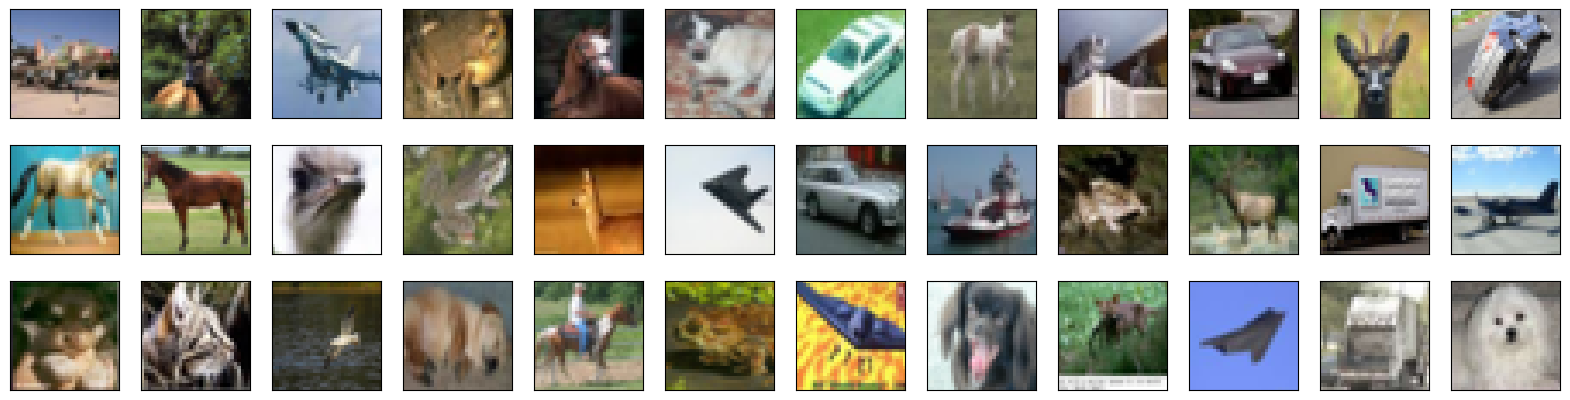

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

fig = plt.figure(figsize=(20,5))
for i in range(36):
    ax = fig.add_subplot(3, 12, i + 1, xticks=[], yticks=[])
    ax.imshow(np.squeeze(x_train[i]))

Uma imagem colorida é uma caixa de números: 32 linhas x 32 colunas x 3 canais (vermelho, verde, azul), cada valor de 0 a 255. **Para a rede, uma foto é só isso: 3.072 números.**

⏱ **Checkpoint 1:** todos veem a grade de imagens?

## Redimensionando as imagens: dividindo cada pixel por 255

In [ ]:
# redimensionamento [0,255] --> [0,1]

x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255

### Por que normalizar os dados?

Redimensionamos os valores dos pixels de 0-255 para 0-1. Este processo, conhecido como **normalização**, é importante por duas razões:

1. **Melhora o treinamento**: redes neurais aprendem melhor quando os números de entrada são pequenos e numa escala parecida. Números grandes fazem o gradiente oscilar.
2. **Evita que um canal domine**: todos os pixels passam a pesar o mesmo no início do treino.

## Dividindo o dataset em treinamento, validação e teste

In [ ]:
from keras.utils import to_categorical

# "one-hot encoding" aplicado aos rótulos: o rótulo 3 (gato) vira [0,0,0,1,0,0,0,0,0,0]
num_classes = 10
y_train = to_categorical(y_train, num_classes)
y_test = to_categorical(y_test, num_classes)

# separando as 1.000 primeiras imagens de treino como validação
(x_train, x_valid) = x_train[1000:], x_train[:1000]
(y_train, y_valid) = y_train[1000:], y_train[:1000]

print("Treinamento:", x_train.shape[0], "imagens")
print("Validação:  ", x_valid.shape[0], "imagens")
print("Teste:      ", x_test.shape[0], "imagens")

Treinamento: 9000 imagens
Validação:   1000 imagens
Teste:       2000 imagens


### Por que 'One-Hot Encoding'?

Os rótulos eram inteiros (0, 1, 2...). Com one-hot, cada rótulo vira um vetor com 10 posições, todas zero menos a da classe correta. Isso casa com a saída da rede, que também tem 10 números: um "quanto a rede acredita" em cada classe. A perda (`categorical_crossentropy`) compara os dois vetores.

### Por que três conjuntos?

- **Treinamento**: a rede ajusta os pesos olhando estas imagens.
- **Validação**: a rede não aprende com elas; servem para saber, a cada época, se ela está aprendendo de verdade ou decorando.
- **Teste**: intocado até o fim. É a única estimativa honesta de como o modelo vai se comportar em produção.

## Definindo a arquitetura do modelo (IMPORTANTE!)

* 3 camadas convolucionais de tamanho progressivamente crescente (32, 64 e 128 filtros)
* Uma camada de "pooling" (2x2) depois de cada convolução
* Uma camada "flatten" para transformar o cubo de números em um vetor
* Dropout para a rede não decorar
* Uma camada totalmente conectada com 128 neurônios
* Última camada totalmente conectada com 10 neurônios (um por classe) e ativação softmax

In [ ]:
from keras.models import Sequential
from keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout

model = Sequential()

# entrada: imagens de 32 x 32 pixels com 3 canais de cor
model.add(Input(shape=(32, 32, 3)))

# 1ª convolução: 32 filtros de 3x3 procuram padrões simples (bordas, cores)
model.add(Conv2D(filters=32, kernel_size=3, padding="same", activation="relu"))
model.add(MaxPooling2D(pool_size=2))      # reduz a imagem de 32x32 para 16x16

# 2ª convolução: 64 filtros combinam bordas em texturas
model.add(Conv2D(filters=64, kernel_size=3, padding="same", activation="relu"))
model.add(MaxPooling2D(pool_size=2))      # 16x16 -> 8x8

# 3ª convolução: 128 filtros combinam texturas em partes de objetos
model.add(Conv2D(filters=128, kernel_size=3, padding="same", activation="relu"))
model.add(MaxPooling2D(pool_size=2))      # 8x8 -> 4x4

# do cubo 4x4x128 para um vetor de 2.048 números
model.add(Flatten())
model.add(Dropout(0.3))                   # desliga 30% dos neurônios a cada passo do treino, contra o overfitting

# camadas totalmente conectadas: decidem a classe
model.add(Dense(128, activation="relu"))
model.add(Dense(10, activation="softmax"))  # 10 saídas que somam 1: a "probabilidade" de cada classe

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

### Entendendo o 'Model Summary'

O `model.summary()` nos dá uma visão geral da arquitetura. Vamos analisar as colunas:

*   **Layer (type)**: o nome e o tipo de cada camada (`Conv2D`, `MaxPooling2D`, `Dense`).
*   **Output Shape**: a forma da saída de cada camada. `None` é o tamanho do lote (definido só no treino). Repare a imagem encolhendo: 32 → 16 → 8 → 4.
*   **Param #**: quantos pesos a camada tem para aprender. A camada `Dense(128)` sozinha tem 262.272, mais que as três convoluções juntas. **Convoluções são baratas porque o mesmo filtro é reutilizado em toda a imagem.**
*   **Total params**: 356.810 números que a rede vai ajustar.

⏱ **Checkpoint 2:** o resumo mostra 10 saídas na última camada?

## Compilando o modelo

In [ ]:
# compilando o modelo escolhendo como se dará nossa perda, otimização e métricas
# mais informações em https://keras.io/api/losses/ e https://keras.io/api/optimizers/

model.compile(loss="categorical_crossentropy",   # a perda: quanto a rede errou (compara os 10 números com o one-hot)
              optimizer="adam",                  # o otimizador: a descida do gradiente, com passo adaptativo
              metrics=["accuracy"])              # a métrica que vamos acompanhar: % de acertos

## Treinando o modelo

O mesmo ciclo do notebook da demo (palpite, erro, culpa, passo), agora em lotes de 128 imagens. Cada **época** passa por todas as 9.000 imagens de treino. Ao fim de cada época, o Keras mede na validação.

O `ModelCheckpoint` guarda os pesos da **melhor época de validação**, não da última.

In [ ]:
from keras.callbacks import ModelCheckpoint
import time

# salva os pesos sempre que a acurácia de validação melhorar
checkpointer = ModelCheckpoint(filepath="model.weights.best.keras", verbose=1, save_best_only=True, monitor="val_accuracy")

inicio = time.time()
hist = model.fit(x_train, y_train,
                 batch_size=128,
                 epochs=10,
                 validation_data=(x_valid, y_valid),
                 callbacks=[checkpointer],
                 verbose=2)
print(f"Tempo de treino: {time.time() - inicio:.0f} segundos")

Epoch 1/10

Epoch 1: val_accuracy improved from None to 0.36000, saving model to model.weights.best.keras

Epoch 1: finished saving model to model.weights.best.keras
71/71 - 30s - 424ms/step - accuracy: 0.2410 - loss: 2.0651 - val_accuracy: 0.3600 - val_loss: 1.7827
Epoch 2/10

Epoch 2: val_accuracy improved from 0.36000 to 0.42600, saving model to model.weights.best.keras

Epoch 2: finished saving model to model.weights.best.keras
71/71 - 18s - 255ms/step - accuracy: 0.3871 - loss: 1.6964 - val_accuracy: 0.4260 - val_loss: 1.5495
Epoch 3/10

Epoch 3: val_accuracy improved from 0.42600 to 0.43700, saving model to model.weights.best.keras

Epoch 3: finished saving model to model.weights.best.keras
71/71 - 17s - 238ms/step - accuracy: 0.4426 - loss: 1.5320 - val_accuracy: 0.4370 - val_loss: 1.5319
Epoch 4/10

Epoch 4: val_accuracy improved from 0.43700 to 0.46000, saving model to model.weights.best.keras

Epoch 4: finished saving model to model.weights.best.keras
71/71 - 17s - 236ms/step

### Analisando o processo de treinamento

A cada época o Keras mostra:

*   **`loss`**: a perda no conjunto de treinamento. Menor é melhor.
*   **`accuracy`**: a acurácia no treinamento.
*   **`val_loss`** e **`val_accuracy`**: o mesmo, medido na validação (imagens que a rede não usa para aprender).

**Como ler:** se `accuracy` sobe e `val_accuracy` para de subir (ou cai), a rede começou a decorar: **overfitting**. Por isso guardamos os pesos da melhor época de validação.

⏱ **Checkpoint 3:** todos terminaram as 10 épocas? (em CPU, 10 a 40 segundos por época)

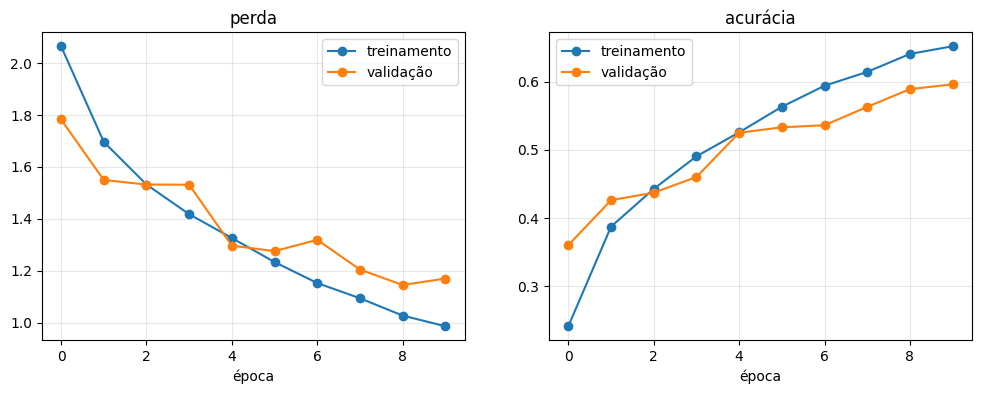

In [23]:
# curvas de treinamento: perda e acurácia por época, treino vs validação

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist.history["loss"], "o-", label="treinamento")
axes[0].plot(hist.history["val_loss"], "o-", label="validação")
axes[0].set_title("perda"); axes[0].set_xlabel("época"); axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].plot(hist.history["accuracy"], "o-", label="treinamento")
axes[1].plot(hist.history["val_accuracy"], "o-", label="validação")
axes[1].set_title("acurácia"); axes[1].set_xlabel("época"); axes[1].legend(); axes[1].grid(alpha=.3)
plt.show()

## Carregando o modelo com a melhor acurácia de validação

In [ ]:
# carregando os pesos que geraram a melhor acurácia de validação

model.load_weights("model.weights.best.keras")

## Cálculo da acurácia no dataset de teste

In [24]:
# avaliando e imprimindo a acurácia do teste (2.000 imagens que o modelo nunca viu)

score = model.evaluate(x_test, y_test, verbose=0)
print("Acurácia de teste:", round(score[1] * 100, 1), "%   (chute aleatório seria 10%)")

Acurácia de teste: 58.4 %   (chute aleatório seria 10%)


## Visualizar algumas predições

As visualizações nos dão pistas sobre por que a rede classifica erroneamente alguns objetos.

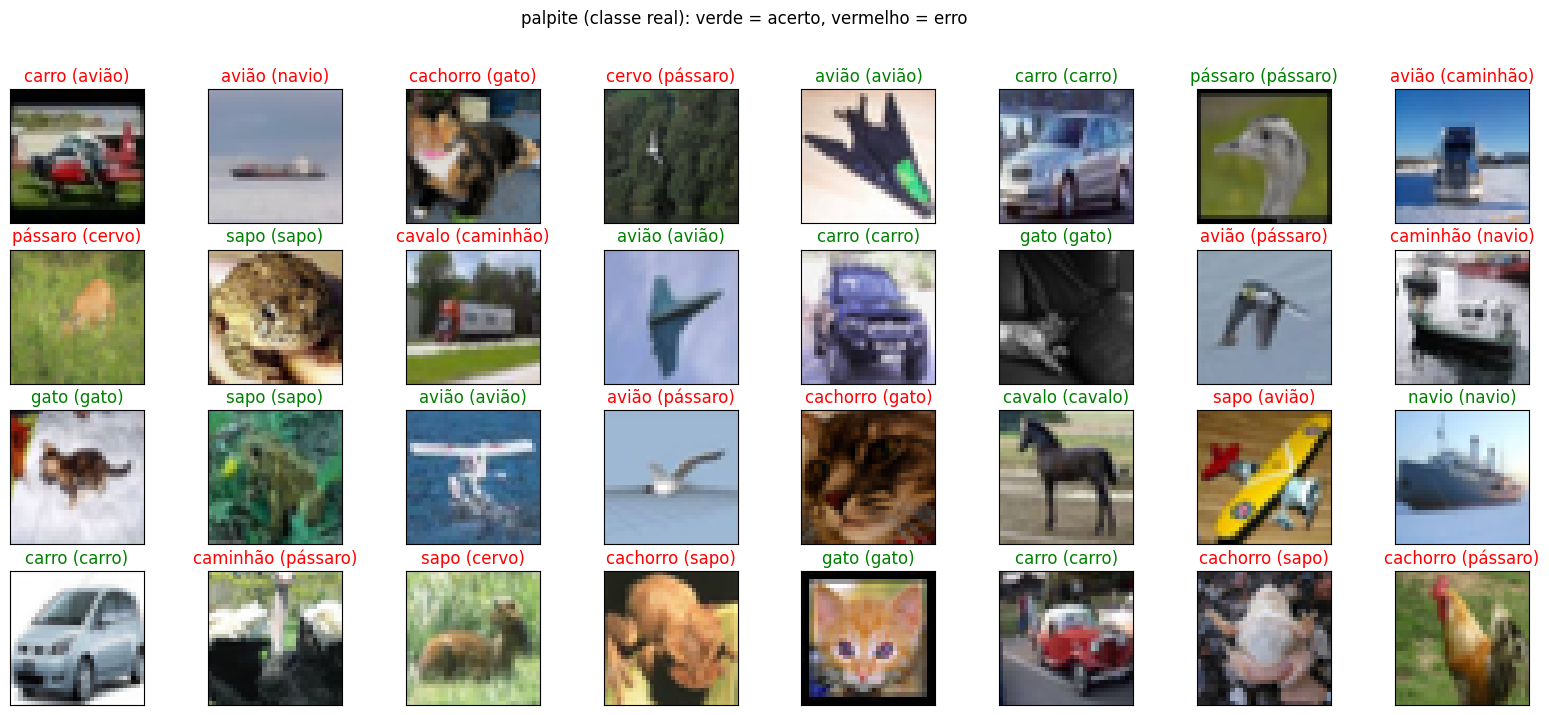

In [25]:
# obtendo previsões no conjunto de teste: para cada imagem, 10 números; a classe prevista é o maior deles

y_hat = model.predict(x_test, verbose=0)

# plot de amostra aleatória de imagens de teste, rótulo predito e rótulo verdadeiro
fig = plt.figure(figsize=(20, 8))
for i, idx in enumerate(np.random.choice(x_test.shape[0], size=32, replace=False)):
    ax = fig.add_subplot(4, 8, i + 1, xticks=[], yticks=[])
    ax.imshow(x_test[idx])
    pred_idx = np.argmax(y_hat[idx])        # classe prevista
    true_idx = np.argmax(y_test[idx])       # classe verdadeira
    ax.set_title("{} ({})".format(cifar10_labels[pred_idx], cifar10_labels[true_idx]),
                 color=("green" if pred_idx == true_idx else "red"))
plt.suptitle("palpite (classe real): verde = acerto, vermelho = erro")
plt.show()

## Matriz de confusão: onde o modelo erra

A acurácia diz *quanto* erra. A matriz de confusão diz *onde*: cada linha é a classe real, cada coluna é o palpite. Em produção, é esse mapa que define onde vale colocar revisão humana.

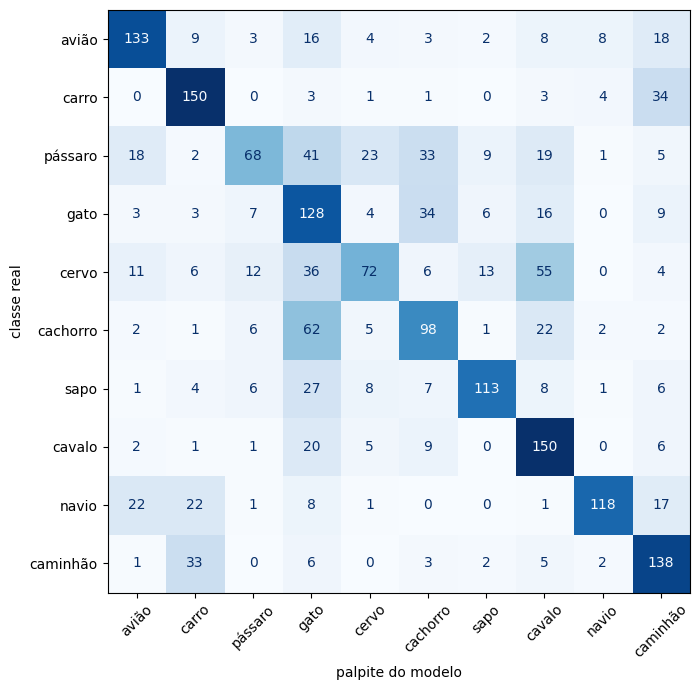

  avião      65%
  carro      77%
  pássaro    31%
  gato       61%
  cervo      33%
  cachorro   49%
  sapo       62%
  cavalo     77%
  navio      62%
  caminhão   73%


In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred = np.argmax(y_hat, axis=1)      # palpites como inteiros 0 a 9
y_true = np.argmax(y_test, axis=1)     # rótulos verdadeiros como inteiros

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=cifar10_labels).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
ax.set_xlabel("palpite do modelo"); ax.set_ylabel("classe real")
plt.tight_layout(); plt.show()

# acurácia por classe: a diagonal dividida pelo total de cada linha
for nome, acertos, total in zip(cifar10_labels, cm.diagonal(), cm.sum(axis=1)):
    print(f"  {nome:<10} {acertos/total:.0%}")

⏱ **Checkpoint 4:** qual foi a sua acurácia no teste? Compare com o vizinho: mesma arquitetura, mesmo dado, números um pouco diferentes. Por quê? (inicialização aleatória dos pesos e ordem dos lotes)

## Registrando o experimento no MLflow

Em um projeto real, cada treino vira um registro: parâmetros, métricas e o arquivo do modelo. No Databricks, isso fica na aba **Experiments**.

In [ ]:
# try:
#     import mlflow
#     with mlflow.start_run(run_name="cnn_cifar10_aula1"):
#         mlflow.log_params({"epocas": 10, "lote": 128, "otimizador": "adam", "n_treino": len(x_train)})
#         mlflow.log_metrics({"acuracia_teste": float(score[1]), "perda_teste": float(score[0]),
#                             "melhor_val_accuracy": float(max(hist.history["val_accuracy"]))})
#         mlflow.log_artifact("model.weights.best.keras")   # o arquivo do modelo vira artefato do run
#     print("Experimento registrado. Veja em Experiments.")
# except Exception as e:
#     print("MLflow indisponível, seguindo sem registro:", e)

## Extra (opcional): o que a CNN "vê"

Os 32 filtros da primeira camada são padrões 3x3 que a rede aprendeu sozinha. Aplicados a uma imagem, geram 32 **mapas de ativação**: onde cada padrão foi encontrado. Isso é o que os slides chamam de "bordas viram texturas, texturas viram partes".

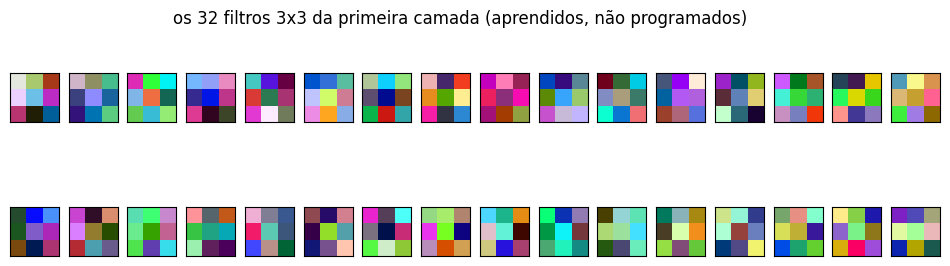

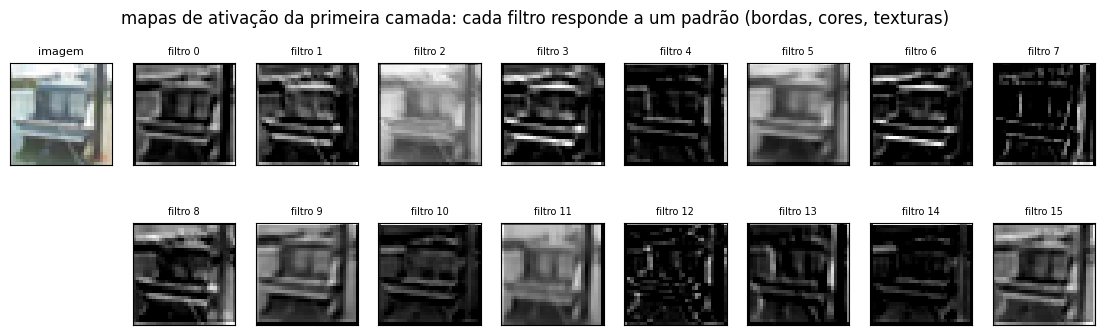

In [ ]:
# os filtros aprendidos pela primeira convolução: formato (3, 3, 3, 32) = altura, largura, canais, filtros
filtros = model.layers[0].get_weights()[0]

fig = plt.figure(figsize=(12, 3.2))
for i in range(32):
    f = filtros[:, :, :, i]
    f = (f - f.min()) / (f.max() - f.min() + 1e-8)      # reescala para 0..1 só para exibir como cor
    ax = fig.add_subplot(2, 16, i + 1, xticks=[], yticks=[]); ax.imshow(f)
plt.suptitle("os 32 filtros 3x3 da primeira camada (aprendidos, não programados)"); plt.show()

# um modelo "parcial" que devolve a saída da primeira convolução para uma imagem de teste
primeira_camada = keras.Model(inputs=model.inputs, outputs=model.layers[0].output)
imagem = x_test[:1]
mapas = primeira_camada.predict(imagem, verbose=0)[0]  # formato (32, 32, 32): altura, largura, filtros

fig = plt.figure(figsize=(14, 3.8))
ax = fig.add_subplot(2, 9, 1, xticks=[], yticks=[]); ax.imshow(imagem[0]); ax.set_title("imagem", fontsize=8)
for k in range(16):
    ax = fig.add_subplot(2, 9, k + 2 + (k // 8), xticks=[], yticks=[]); ax.imshow(mapas[:, :, k], cmap="gray"); ax.set_title(f"filtro {k}", fontsize=7)
plt.suptitle("mapas de ativação da primeira camada: cada filtro responde a um padrão (bordas, cores, texturas)"); plt.show()

## Para discutir

1. Com 9.000 imagens e 10 épocas em CPU chegamos a uma acurácia na casa dos 60%. O que mudaria com 50.000 imagens, 30 épocas e GPU? (Com o dataset completo e GPU, redes desta família passam de 80%.)
2. Olhando a matriz de confusão: quais pares de classes se confundem? Onde você colocaria revisão humana?
3. Treinar do zero exigiu milhares de exemplos rotulados. **Na aula 4** vamos reaproveitar uma rede já treinada em milhões de imagens e resolver um problema novo com dezenas de exemplos: transfer learning.

**Próximo notebook:** em vez de dizer *o que* há na foto, vamos dizer *onde*: detecção de objetos.